# Phase 6 — Part 1 of 3: seismic matching and 4D SEG-Y checkpoints
Run original cells through **Cell 15** and then the checkpoint export cell. Outputs are reusable SEG-Y with matching trace order and baseline X/Y. This stage reads the original SEG-Y inputs and is only rerun when they change. **Disk usage:** expect approximately 3 × trace count × sample count × 4 bytes plus temporary output. Do not run subsequent stages in this notebook.

In [1]:
%pip install -U openai numpy pandas scipy matplotlib plotly
%pip install -U obspy segyio lasio ipywidgets
%pip install -U scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.5.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 29.8 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 23.4 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 26.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 6.9 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 9.9 MB/s  0:00:00
   ━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/11 [numpy]  WARNING: The scripts f2py and numpy-config are installed in '/home/apgce_team_08/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━

In [2]:
import os
import gc
import segyio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ==========================================
# SEG-Y FILE PATHS
# ==========================================

baseline_path = "/home/apgce_team_08/Baseline_Matched.sgy"

monitor_path = (
    "/data/epic20/APGCE/input_data/challenge3/"
    "volumes/Challenge3_Monitor_FilteredScaled_FullStack.sgy"
)

def load_seismic_geometry(filepath, survey_name):

    if not os.path.isfile(filepath):
        raise FileNotFoundError(filepath)

    print(f"\nLoading {survey_name}...")

    with segyio.open(
        filepath,
        "r",
        ignore_geometry=True
    ) as f:

        f.mmap()

        # ==================================
        # SEISMIC AMPLITUDES
        # ==================================

        seismic = segyio.tools.collect(f.trace[:])

        # ==================================
        # SAMPLING INFORMATION
        # ==================================

        samples = np.asarray(
            f.samples,
            dtype=np.float64
        )

        dt_ms = (
            f.bin[segyio.BinField.Interval] / 1000.0
        )

        # ==================================
        # INLINE AND CROSSLINE
        # ==================================

        inline = np.asarray(
            f.attributes(
                segyio.TraceField.INLINE_3D
            )[:],
            dtype=np.int32
        )

        crossline = np.asarray(
            f.attributes(
                segyio.TraceField.CROSSLINE_3D
            )[:],
            dtype=np.int32
        )

        # ==================================
        # STANDARD CDP X/Y HEADERS
        # ==================================

        x_raw = np.asarray(
            f.attributes(
                segyio.TraceField.CDP_X
            )[:],
            dtype=np.float64
        )

        y_raw = np.asarray(
            f.attributes(
                segyio.TraceField.CDP_Y
            )[:],
            dtype=np.float64
        )

        scalar = np.asarray(
            f.attributes(
                segyio.TraceField.SourceGroupScalar
            )[:],
            dtype=np.int32
        )

        # ==================================
        # APPLY COORDINATE SCALAR
        # ==================================

        scale = np.ones(
            f.tracecount,
            dtype=np.float64
        )

        positive = scalar > 0
        negative = scalar < 0

        scale[positive] = scalar[positive]

        scale[negative] = (
            1.0 /
            np.abs(scalar[negative].astype(np.float64))
        )

        x = x_raw * scale
        y = y_raw * scale

        # ==================================
        # GEOMETRY DATAFRAME
        # ==================================

        geometry = pd.DataFrame({

            "Trace_Index": np.arange(
                f.tracecount,
                dtype=np.int64
            ),

            "Inline": inline,
            "Crossline": crossline,

            "X": x,
            "Y": y,

            "X_Raw": x_raw,
            "Y_Raw": y_raw,

            "Coordinate_Scalar": scalar
        })

    print(f"{survey_name} loaded successfully")
    print("Seismic shape:", seismic.shape)
    print("Trace count:", len(geometry))

    print(
        "Inline range:",
        inline.min(), "-", inline.max()
    )

    print(
        "Crossline range:",
        crossline.min(), "-", crossline.max()
    )

    print("Sampling interval:", dt_ms, "ms")

    if survey_name.lower() == "baseline":
        print("Baseline X range:", np.nanmin(x), np.nanmax(x))
        print("Baseline Y range:", np.nanmin(y), np.nanmax(y))
    else:
        print("Monitor X/Y headers read but not trusted.")

    return seismic, geometry, samples, dt_ms
    
print("\nCell 3 initialized successfully.")


Cell 3 initialized successfully.


In [3]:
# ==========================================
# LOAD BASELINE
# ==========================================

(
    baseline,
    baseline_geometry,
    baseline_samples,
    baseline_dt
) = load_seismic_geometry(
    baseline_path,
    "Baseline"
)

# ==========================================
# LOAD MONITOR
# ==========================================

(
    monitor,
    monitor_geometry,
    monitor_samples,
    monitor_dt
) = load_seismic_geometry(
    monitor_path,
    "Monitor"
)

print("\n====================================")
print("ORIGINAL SURVEY TRACE COUNTS")
print("====================================")

print("Baseline:", f"{baseline.shape[0]:,}")
print("Monitor :", f"{monitor.shape[0]:,}")
print(
    "Difference:",
    f"{abs(baseline.shape[0] - monitor.shape[0]):,}"
)

print("\nCell 4 initialized successfully.")


Loading Baseline...
Baseline loaded successfully
Seismic shape: (1240941, 1301)
Trace count: 1240941
Inline range: 344 - 1372
Crossline range: 1949 - 3196
Sampling interval: 2.0 ms
Baseline X range: 454088.0 478817.0
Baseline Y range: 564114.0 586543.0

Loading Monitor...
Monitor loaded successfully
Seismic shape: (1244028, 1301)
Trace count: 1244028
Inline range: 344 - 1372
Crossline range: 1946 - 3196
Sampling interval: 2.0 ms
Monitor X/Y headers read but not trusted.

ORIGINAL SURVEY TRACE COUNTS
Baseline: 1,240,941
Monitor : 1,244,028
Difference: 3,087

Cell 4 initialized successfully.


In [4]:
# ==========================================
# VALIDATE UNIQUE INLINE/CROSSLINE BINS
# ==========================================

keys = ["Inline", "Crossline"]

for name, geom in [
    ("Baseline", baseline_geometry),
    ("Monitor", monitor_geometry)
]:

    duplicates = geom.duplicated(keys).sum()

    print(f"{name} duplicate IL/XL bins: {duplicates:,}")

    if duplicates > 0:
        raise ValueError(
            f"{name} contains duplicate Inline/Crossline "
            "pairs. Resolve these before matching."
        )

# ==========================================
# VALIDATE SAMPLE AXES
# ==========================================

if baseline.shape[1] != monitor.shape[1]:
    raise ValueError(
        "Baseline and Monitor have different sample counts."
    )

if not np.isclose(baseline_dt, monitor_dt):
    raise ValueError(
        "Baseline and Monitor sampling intervals differ."
    )

if not np.allclose(
    baseline_samples,
    monitor_samples,
    atol=1e-4,
    rtol=0
):
    raise ValueError(
        "Baseline and Monitor sample time axes differ."
    )

# ==========================================
# SELECT BASELINE REFERENCE GEOMETRY
# ==========================================

baseline_reference = baseline_geometry[
    [
        "Inline",
        "Crossline",
        "Trace_Index",
        "X",
        "Y"
    ]
].copy()

monitor_reference = monitor_geometry[
    [
        "Inline",
        "Crossline",
        "Trace_Index"
    ]
].copy()

# ==========================================
# MATCH COMMON INLINE/CROSSLINE BINS
# ==========================================

matched_geometry = pd.merge(
    baseline_reference,
    monitor_reference,
    on=["Inline", "Crossline"],
    how="inner",
    suffixes=("_baseline", "_monitor"),
    validate="one_to_one",
    sort=False
)

# Retain original Baseline trace ordering
matched_geometry = (
    matched_geometry
    .sort_values("Trace_Index_baseline")
    .reset_index(drop=True)
)

# ==========================================
# VERIFY MATCHING
# ==========================================

n_baseline = len(baseline_geometry)
n_monitor = len(monitor_geometry)
n_matched = len(matched_geometry)

if n_matched == 0:
    raise ValueError(
        "No matching Inline/Crossline pairs found."
    )

print("\n====================================")
print("TRACE MATCHING SUMMARY")
print("====================================")

print("Original Baseline:", f"{n_baseline:,}")
print("Original Monitor :", f"{n_monitor:,}")
print("Matched traces  :", f"{n_matched:,}")

print(
    "Unmatched Baseline:",
    f"{n_baseline - n_matched:,}"
)

print(
    "Unmatched Monitor:",
    f"{n_monitor - n_matched:,}"
)

print(
    "Baseline matching coverage:",
    f"{100 * n_matched / n_baseline:.2f}%"
)

print(
    "Monitor matching coverage:",
    f"{100 * n_matched / n_monitor:.2f}%"
)

print("\nMatched geometry preview:")
display(matched_geometry.head())
print("\nCell 5 initialized successfully.")

Baseline duplicate IL/XL bins: 0
Monitor duplicate IL/XL bins: 0

TRACE MATCHING SUMMARY
Original Baseline: 1,240,941
Original Monitor : 1,244,028
Matched traces  : 1,240,941
Unmatched Baseline: 0
Unmatched Monitor: 3,087
Baseline matching coverage: 100.00%
Monitor matching coverage: 99.75%

Matched geometry preview:


,Inline,Crossline,Trace_Index_baseline,X,Y,Trace_Index_monitor
0,344,2016,0,462919.0,564114.0,3
1,344,2017,1,462912.0,564124.0,4
2,344,2018,2,462904.0,564134.0,5
3,344,2019,3,462897.0,564144.0,6
4,344,2020,4,462889.0,564154.0,7



Cell 5 initialized successfully.


In [5]:
# ==========================================
# GET MATCHED TRACE INDICES
# ==========================================

baseline_indices = matched_geometry[
    "Trace_Index_baseline"
].to_numpy(dtype=np.int64)

monitor_indices = matched_geometry[
    "Trace_Index_monitor"
].to_numpy(dtype=np.int64)

# ==========================================
# MATCH SEISMIC AMPLITUDES
# ==========================================

baseline_matched = np.ascontiguousarray(
    baseline[baseline_indices],
    dtype=np.float32
)

monitor_matched = np.ascontiguousarray(
    monitor[monitor_indices],
    dtype=np.float32
)

# ==========================================
# VALIDATION
# ==========================================

assert baseline_matched.shape == monitor_matched.shape

assert baseline_matched.shape[0] == len(matched_geometry)

print("\n====================================")
print("MATCHED SEISMIC VOLUMES")
print("====================================")

print("Baseline matched:", baseline_matched.shape)
print("Monitor matched :", monitor_matched.shape)

print(
    "Identical trace count:",
    baseline_matched.shape[0] ==
    monitor_matched.shape[0]
)

print("Matching completed successfully.")
print("\nCell 6 initialized successfully.")


MATCHED SEISMIC VOLUMES
Baseline matched: (1240941, 1301)
Monitor matched : (1240941, 1301)
Identical trace count: True
Matching completed successfully.

Cell 6 initialized successfully.


In [6]:
# ==========================================
# MONITOR GEOMETRY IN MATCHED TRACE ORDER
# ==========================================

monitor_geometry_matched = matched_geometry[
    [
        "Inline",
        "Crossline",
        "Trace_Index_monitor",
        "X",
        "Y"
    ]
].copy()

monitor_geometry_matched = (
    monitor_geometry_matched
    .rename(columns={
        "Trace_Index_monitor": "Trace_Index"
    })
)

# ==========================================
# UPDATE ORIGINAL-ORDER MONITOR GEOMETRY
# ==========================================

# Preserve original header values for reference
monitor_geometry["X_Original"] = monitor_geometry["X"]
monitor_geometry["Y_Original"] = monitor_geometry["Y"]

# Monitor header coordinates are not trusted
monitor_geometry["X"] = np.nan
monitor_geometry["Y"] = np.nan

# Assign Baseline coordinates to matched Monitor traces
monitor_geometry.loc[
    monitor_indices, "X"
] = matched_geometry["X"].to_numpy()

monitor_geometry.loc[
    monitor_indices, "Y"
] = matched_geometry["Y"].to_numpy()

# ==========================================
# VERIFICATION
# ==========================================

assert np.array_equal(
    monitor_geometry_matched["X"].to_numpy(),
    matched_geometry["X"].to_numpy()
)

assert np.array_equal(
    monitor_geometry_matched["Y"].to_numpy(),
    matched_geometry["Y"].to_numpy()
)

print("\n====================================")
print("MONITOR X/Y REPLACEMENT")
print("====================================")

print(
    "Matched Monitor traces with Baseline X/Y:",
    f"{len(monitor_geometry_matched):,}"
)

print(
    "Unmatched Monitor traces with unknown X/Y:",
    f"{len(monitor_geometry) - len(monitor_geometry_matched):,}"
)

print("\nMatched Monitor geometry preview:")
display(monitor_geometry_matched.head())
print("\nCell 7 initialized successfully.")


MONITOR X/Y REPLACEMENT
Matched Monitor traces with Baseline X/Y: 1,240,941
Unmatched Monitor traces with unknown X/Y: 3,087

Matched Monitor geometry preview:


,Inline,Crossline,Trace_Index,X,Y
0,344,2016,3,462919.0,564114.0
1,344,2017,4,462912.0,564124.0
2,344,2018,5,462904.0,564134.0
3,344,2019,6,462897.0,564144.0
4,344,2020,7,462889.0,564154.0



Cell 7 initialized successfully.


FINAL GEOMETRY QC
Matched traces: 1,240,941
Valid X/Y pairs: 1,240,941
Invalid X/Y pairs: 0
X range: 454088.0 - 478817.0
Y range: 564114.0 - 586543.0

SEISMIC AMPLITUDE QC
Baseline NaNs: 0
Monitor NaNs: 6,437,783


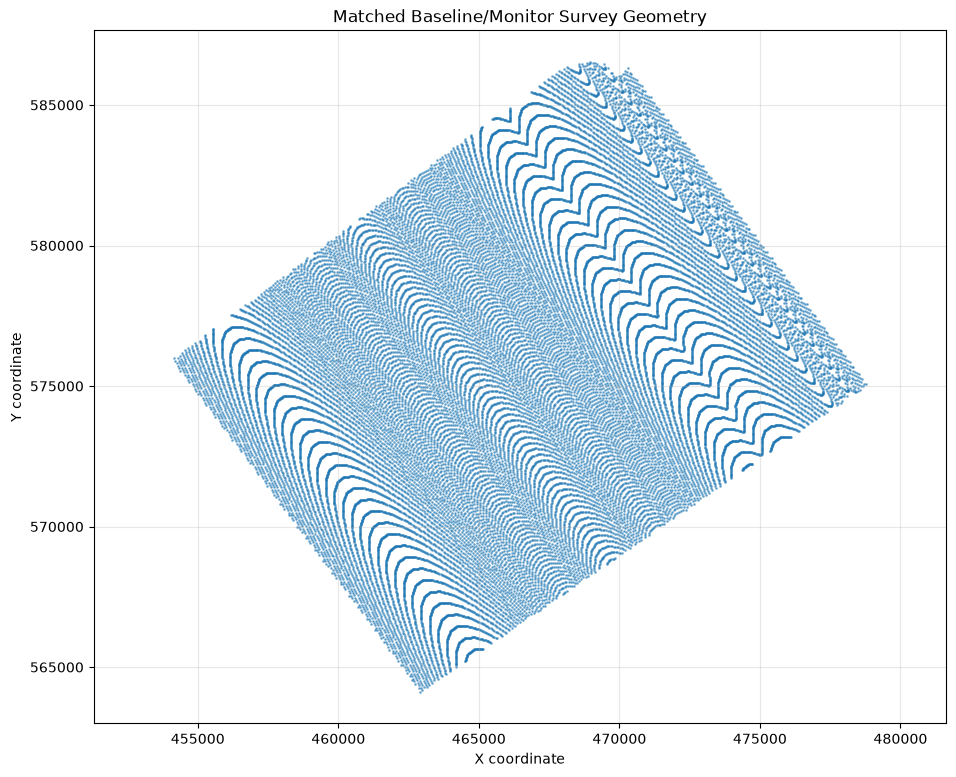


Geometry and trace matching QC completed.

Cell 8 initialized successfully.


In [7]:
# ==========================================
# 1. TRACE ALIGNMENT
# ==========================================

assert baseline_matched.shape == monitor_matched.shape

assert len(matched_geometry) == baseline_matched.shape[0]

assert np.array_equal(
    matched_geometry["Inline"].to_numpy(),
    baseline_geometry.iloc[
        baseline_indices
    ]["Inline"].to_numpy()
)

assert np.array_equal(
    matched_geometry["Crossline"].to_numpy(),
    monitor_geometry.iloc[
        monitor_indices
    ]["Crossline"].to_numpy()
)

# ==========================================
# 2. COORDINATE VALIDITY
# ==========================================

x = matched_geometry["X"].to_numpy()
y = matched_geometry["Y"].to_numpy()

valid_xy = (
    np.isfinite(x) &
    np.isfinite(y)
)

print("====================================")
print("FINAL GEOMETRY QC")
print("====================================")

print("Matched traces:", f"{len(matched_geometry):,}")

print(
    "Valid X/Y pairs:",
    f"{np.count_nonzero(valid_xy):,}"
)

print(
    "Invalid X/Y pairs:",
    f"{np.count_nonzero(~valid_xy):,}"
)

print("X range:", np.nanmin(x), "-", np.nanmax(x))
print("Y range:", np.nanmin(y), "-", np.nanmax(y))

# ==========================================
# 3. SEISMIC NaN QC
# ==========================================

print("\n====================================")
print("SEISMIC AMPLITUDE QC")
print("====================================")

print(
    "Baseline NaNs:",
    f"{np.isnan(baseline_matched).sum():,}"
)

print(
    "Monitor NaNs:",
    f"{np.isnan(monitor_matched).sum():,}"
)

# ==========================================
# 4. SURVEY GEOMETRY PLOT
# ==========================================

# Plot a subset to avoid rendering
# more than one million points

step = max(1, len(matched_geometry) // 30000)

fig, ax = plt.subplots(figsize=(11, 9))

ax.scatter(
    x[::step],
    y[::step],
    s=1,
    alpha=0.5
)

ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_title("Matched Baseline/Monitor Survey Geometry")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

plt.show()

print("\nGeometry and trace matching QC completed.")
print("\nCell 8 initialized successfully.")

In [8]:
if not np.isclose(baseline_dt, monitor_dt):
    raise ValueError("Baseline and monitor sampling intervals differ.")

if not np.allclose(baseline_samples, monitor_samples):
    raise ValueError("Baseline and monitor time axes differ.")

print("Time sampling is compatible.")
print("\nCell 9 initialized successfully.")

Time sampling is compatible.

Cell 9 initialized successfully.


Trace alignment: PASSED

GEOMETRY QC
Matched traces: 1,240,941
Valid X/Y pairs: 1,240,941
X range: 454088.0 - 478817.0
Y range: 564114.0 - 586543.0

AMPLITUDE QC
Baseline NaNs: 0
Monitor NaNs: 6,437,783

Calculating 4D difference...
4D difference shape: (1240941, 1301)
4D difference NaNs: 6,437,783

Writing 4D difference SEG-Y...
Written 100,000 / 1,240,941 traces
Written 200,000 / 1,240,941 traces
Written 300,000 / 1,240,941 traces
Written 400,000 / 1,240,941 traces
Written 500,000 / 1,240,941 traces
Written 600,000 / 1,240,941 traces
Written 700,000 / 1,240,941 traces
Written 800,000 / 1,240,941 traces
Written 900,000 / 1,240,941 traces
Written 1,000,000 / 1,240,941 traces
Written 1,100,000 / 1,240,941 traces
Written 1,200,000 / 1,240,941 traces

4D DIFFERENCE EXPORT COMPLETED
Output: /home/apgce_team_08/4D_difference.sgy

Verifying exported SEG-Y...
Exported trace count: 1240941
Samples per trace: 1301
SEG-Y sample format: 5
Trace 0 | IL=344 | XL=2016 | X=462919.00 | Y=564114.00
Tra

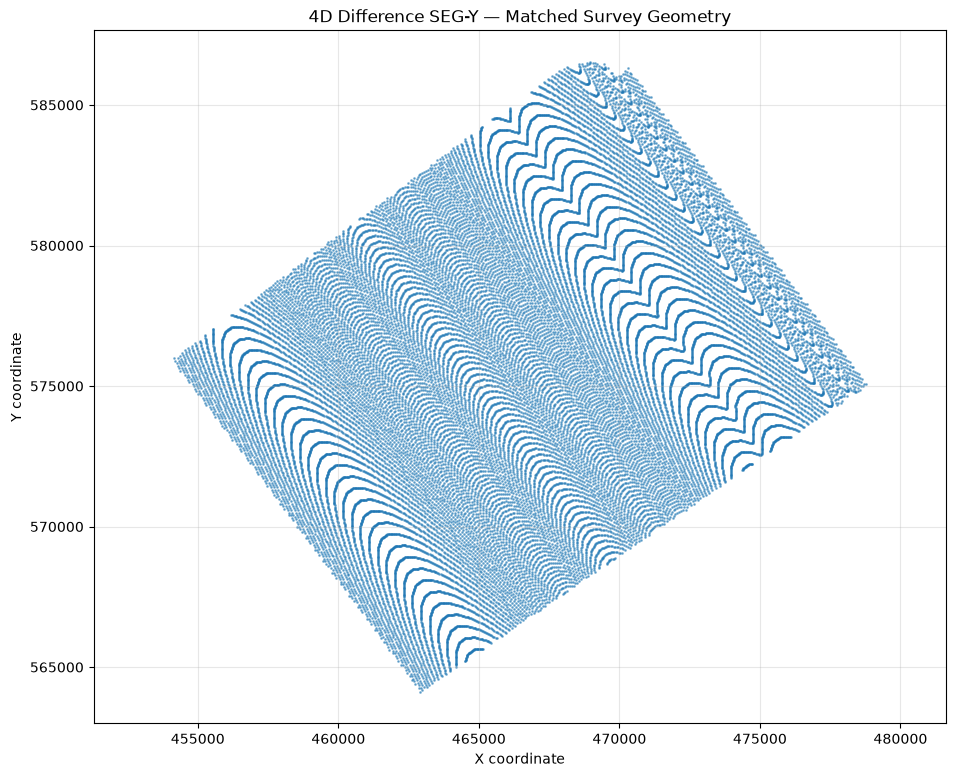


All processing completed.

Cell 10 initialized successfully.


In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
import segyio

# ==========================================
# FILE PATHS
# ==========================================

baseline_path = "/home/apgce_team_08/Baseline_Matched.sgy"

output_path = "/home/apgce_team_08/4D_difference.sgy"

# ==========================================
# 1. TRACE ALIGNMENT QC
# ==========================================

assert baseline_matched.shape == monitor_matched.shape

assert len(matched_geometry) == baseline_matched.shape[0]

baseline_indices = matched_geometry[
    "Trace_Index_baseline"
].to_numpy(dtype=np.int64)

monitor_indices = matched_geometry[
    "Trace_Index_monitor"
].to_numpy(dtype=np.int64)

assert np.array_equal(
    matched_geometry["Inline"].to_numpy(),
    baseline_geometry.iloc[
        baseline_indices
    ]["Inline"].to_numpy()
)

assert np.array_equal(
    matched_geometry["Crossline"].to_numpy(),
    monitor_geometry.iloc[
        monitor_indices
    ]["Crossline"].to_numpy()
)

print("Trace alignment: PASSED")

# ==========================================
# 2. COORDINATE VALIDITY QC
# ==========================================

x = matched_geometry["X"].to_numpy(dtype=np.float64)
y = matched_geometry["Y"].to_numpy(dtype=np.float64)

valid_xy = np.isfinite(x) & np.isfinite(y)

if not np.all(valid_xy):
    raise ValueError(
        "Some matched traces have invalid X/Y coordinates."
    )

print("\n====================================")
print("GEOMETRY QC")
print("====================================")

print("Matched traces:", f"{len(matched_geometry):,}")
print("Valid X/Y pairs:", f"{valid_xy.sum():,}")

print("X range:", np.min(x), "-", np.max(x))
print("Y range:", np.min(y), "-", np.max(y))

# ==========================================
# 3. SEISMIC AMPLITUDE QC
# ==========================================

print("\n====================================")
print("AMPLITUDE QC")
print("====================================")

print("Baseline NaNs:", f"{np.isnan(baseline_matched).sum():,}")
print("Monitor NaNs:", f"{np.isnan(monitor_matched).sum():,}")

# ==========================================
# 4. CALCULATE 4D DIFFERENCE
# ==========================================

print("\nCalculating 4D difference...")

# Preserve NaNs; do not drop or interpolate traces.
difference_4d = (
    monitor_matched.astype(np.float32, copy=False)
    - baseline_matched.astype(np.float32, copy=False)
)

print("4D difference shape:", difference_4d.shape)
print("4D difference NaNs:", f"{np.isnan(difference_4d).sum():,}")

# ==========================================
# 5. EXPORT SEG-Y WITH BASELINE X/Y
# ==========================================

print("\nWriting 4D difference SEG-Y...")

with segyio.open(
    baseline_path,
    "r",
    ignore_geometry=True
) as src:

    spec = segyio.spec()

    spec.samples = src.samples
    spec.format = 5  # IEEE 32-bit floating point
    spec.tracecount = difference_4d.shape[0]

    with segyio.create(output_path, spec) as dst:

        # Copy binary header
        dst.bin = src.bin

        # Explicitly enforce IEEE float format
        dst.bin[segyio.BinField.Format] = 5

        # Copy textual header
        dst.text[0] = src.text[0]

        for i in range(difference_4d.shape[0]):

            original_baseline_index = int(
                baseline_indices[i]
            )

            # Copy original Baseline trace header
            header = dict(
                src.header[original_baseline_index]
            )

            # Matched Inline/Crossline
            header[segyio.TraceField.INLINE_3D] = int(
                matched_geometry.iloc[i]["Inline"]
            )

            header[segyio.TraceField.CROSSLINE_3D] = int(
                matched_geometry.iloc[i]["Crossline"]
            )

            # ----------------------------------
            # BASELINE X/Y COORDINATES
            # ----------------------------------

            # Retrieve original coordinate scalar
            scalar = int(
                header.get(
                    segyio.TraceField.SourceGroupScalar,
                    1
                )
            )

            if scalar > 0:
                x_raw = int(round(x[i] / scalar))
                y_raw = int(round(y[i] / scalar))

            elif scalar < 0:
                x_raw = int(round(x[i] * abs(scalar)))
                y_raw = int(round(y[i] * abs(scalar)))

            else:
                x_raw = int(round(x[i]))
                y_raw = int(round(y[i]))

            # Write X/Y to standard CDP coordinate headers
            header[segyio.TraceField.CDP_X] = x_raw
            header[segyio.TraceField.CDP_Y] = y_raw

            # Write updated trace header
            dst.header[i] = header

            # Write 4D difference amplitude
            dst.trace[i] = difference_4d[i]

            if (i + 1) % 100000 == 0:
                print(
                    f"Written {i + 1:,} / "
                    f"{difference_4d.shape[0]:,} traces"
                )

        dst.flush()

print("\n====================================")
print("4D DIFFERENCE EXPORT COMPLETED")
print("====================================")
print("Output:", output_path)

# ==========================================
# 6. VERIFY OUTPUT SEG-Y HEADERS
# ==========================================

print("\nVerifying exported SEG-Y...")

with segyio.open(
    output_path,
    "r",
    ignore_geometry=True
) as f:

    print("Exported trace count:", f.tracecount)
    print("Samples per trace:", len(f.samples))

    print(
        "SEG-Y sample format:",
        f.bin[segyio.BinField.Format]
    )

    check_indices = np.unique(
        np.linspace(
            0,
            f.tracecount - 1,
            min(5, f.tracecount),
            dtype=np.int64
        )
    )

    for i in check_indices:

        h = f.header[int(i)]

        scalar = int(
            h[segyio.TraceField.SourceGroupScalar]
        )

        if scalar > 0:
            factor = float(scalar)
        elif scalar < 0:
            factor = 1.0 / abs(scalar)
        else:
            factor = 1.0

        exported_x = (
            h[segyio.TraceField.CDP_X] * factor
        )

        exported_y = (
            h[segyio.TraceField.CDP_Y] * factor
        )

        print(
            f"Trace {i:,} | "
            f"IL={h[segyio.TraceField.INLINE_3D]} | "
            f"XL={h[segyio.TraceField.CROSSLINE_3D]} | "
            f"X={exported_x:.2f} | "
            f"Y={exported_y:.2f}"
        )

        if not np.isclose(exported_x, x[i], atol=0.01):
            raise ValueError(
                f"X coordinate mismatch at trace {i}"
            )

        if not np.isclose(exported_y, y[i], atol=0.01):
            raise ValueError(
                f"Y coordinate mismatch at trace {i}"
            )

    print("\nSampled coordinate verification: PASSED")

# ==========================================
# 7. SURVEY GEOMETRY PLOT
# ==========================================

step = max(1, len(matched_geometry) // 30000)

fig, ax = plt.subplots(figsize=(11, 9))

ax.scatter(
    x[::step],
    y[::step],
    s=1,
    alpha=0.5
)

ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_title("4D Difference SEG-Y — Matched Survey Geometry")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

plt.show()

print("\nAll processing completed.")
print("\nCell 10 initialized successfully.")

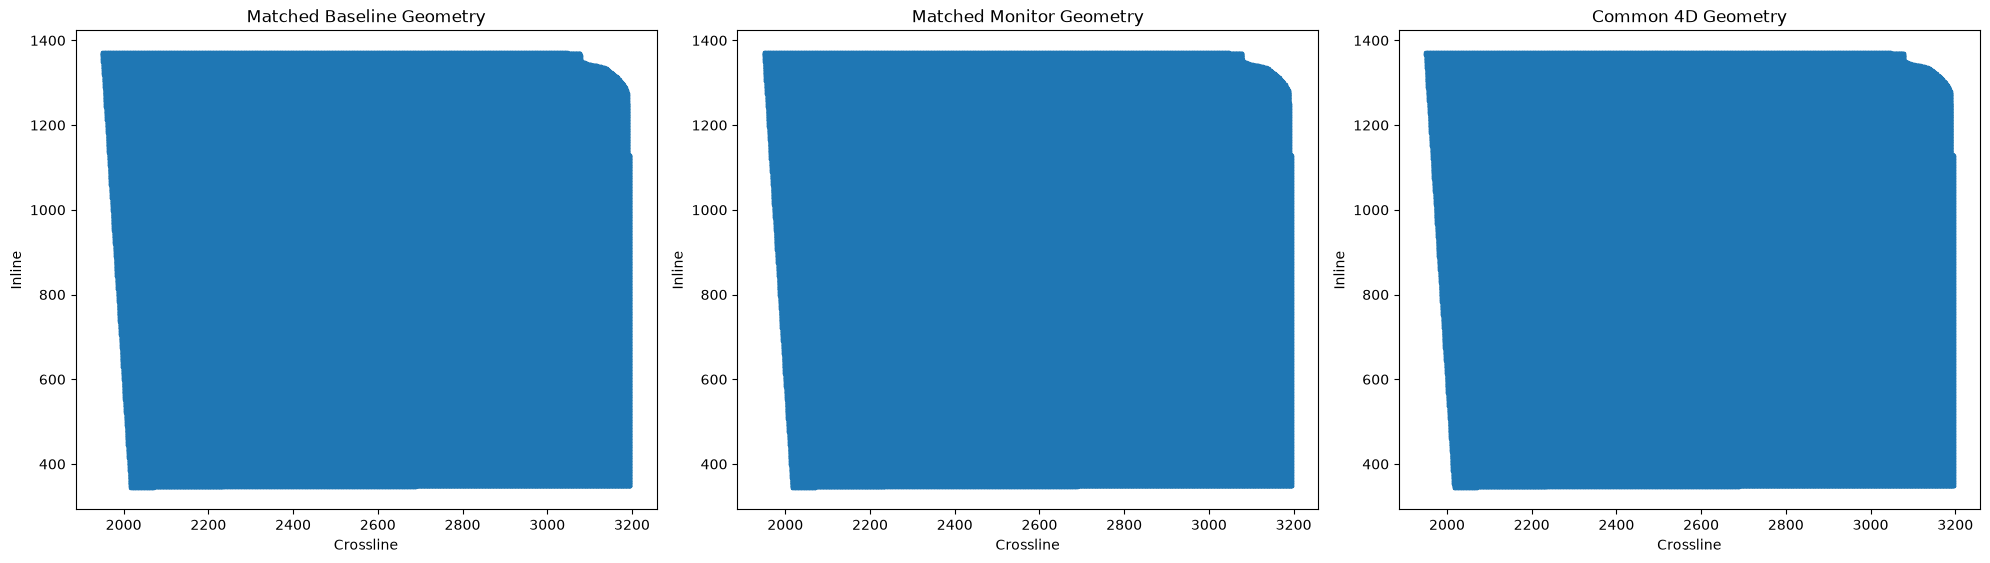


Cell 11 initialized successfully.


In [10]:
import matplotlib.pyplot as plt

# Extract inline and crossline
inline = matched_geometry["Inline"].values
crossline = matched_geometry["Crossline"].values

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Baseline
axes[0].scatter(
    crossline,
    inline,
    s=2
)
axes[0].set_title("Matched Baseline Geometry")

# Monitor
axes[1].scatter(
    crossline,
    inline,
    s=2
)
axes[1].set_title("Matched Monitor Geometry")

# Difference
axes[2].scatter(
    crossline,
    inline,
    s=2
)
axes[2].set_title("Common 4D Geometry")

for ax in axes:
    ax.set_xlabel("Crossline")
    ax.set_ylabel("Inline")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()
print("\nCell 11 initialized successfully.")

In [11]:
matched_geometry.to_csv(
    "/home/apgce_team_08/4D_Matched_Inline_Crossline.csv",
    index=False
)

print("Matched geometry CSV saved.")
print("\nCell 12 initialized successfully.")

Matched geometry CSV saved.

Cell 12 initialized successfully.


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display

# ==========================================
# 1. VALIDATE EXISTING DATA
# ==========================================

volumes = {
    "Baseline": baseline_matched,
    "Monitor": monitor_matched,
    "4D Difference": difference_4d
}

geometry = matched_geometry.reset_index(drop=True)

inline_values = np.sort(geometry["Inline"].unique())
crossline_values = np.sort(geometry["Crossline"].unique())

samples_ms = np.asarray(baseline_samples, dtype=float)

n_traces = len(geometry)
n_samples = len(samples_ms)

for name, volume in volumes.items():
    if volume.shape != (n_traces, n_samples):
        raise ValueError(f"{name}: shape mismatch")

if geometry.duplicated(["Inline", "Crossline"]).any():
    raise ValueError("Duplicate Inline/Crossline positions found.")

if not np.all(np.diff(samples_ms) > 0):
    raise ValueError("Sample axis must be strictly increasing.")

# ==========================================
# 2. BUILD TRACE LOOKUP
# ==========================================

# Maps (Inline, Crossline) to the matched trace index.
# No seismic amplitudes are copied.

trace_lookup = pd.Series(
    np.arange(n_traces, dtype=np.int64),
    index=pd.MultiIndex.from_frame(
        geometry[["Inline", "Crossline"]]
    )
)

# ==========================================
# 3. REPORT GEOMETRY
# ==========================================

print("SEISMIC VIEWER READY")
print("=============================")
print("Traces:", f"{n_traces:,}")
print("Samples per trace:", n_samples)
print("Inline range:", inline_values.min(), "-", inline_values.max())
print("Crossline range:", crossline_values.min(), "-", crossline_values.max())
print("Time range (ms):", samples_ms.min(), "-", samples_ms.max())
print("Sample interval (ms):", baseline_dt)
print("NaN samples are preserved.")
print("\nCell 13 initialized successfully.")

SEISMIC VIEWER READY
Traces: 1,240,941
Samples per trace: 1301
Inline range: 344 - 1372
Crossline range: 1949 - 3196
Time range (ms): 0.0 - 2600.0
Sample interval (ms): 2.0
NaN samples are preserved.

Cell 13 initialized successfully.


In [13]:

def extract_inline(volume, inline_number):
    """Return [time samples, crosslines] for one inline."""

    idx = trace_lookup.loc[inline_number]

    section = np.full(
        (n_samples, len(crossline_values)),
        np.nan,
        dtype=np.float32
    )

    positions = np.searchsorted(
        crossline_values,
        idx.index.to_numpy()
    )

    section[:, positions] = volume[
        idx.to_numpy(dtype=np.int64), :
    ].T

    return section


def extract_crossline(volume, crossline_number):
    """Return [time samples, inlines] for one crossline."""

    idx = trace_lookup.xs(crossline_number, level="Crossline")

    section = np.full(
        (n_samples, len(inline_values)),
        np.nan,
        dtype=np.float32
    )

    positions = np.searchsorted(
        inline_values,
        idx.index.to_numpy()
    )

    section[:, positions] = volume[
        idx.to_numpy(dtype=np.int64), :
    ].T

    return section


def extract_time_slice(volume, time_ms):
    """Return [inlines, crosslines] for nearest time sample."""

    sample_idx = int(np.argmin(np.abs(samples_ms - time_ms)))

    slice_data = np.full(
        (len(inline_values), len(crossline_values)),
        np.nan,
        dtype=np.float32
    )

    inline_positions = np.searchsorted(
        inline_values,
        geometry["Inline"].to_numpy()
    )

    crossline_positions = np.searchsorted(
        crossline_values,
        geometry["Crossline"].to_numpy()
    )

    slice_data[inline_positions, crossline_positions] = (
        volume[:, sample_idx]
    )

    return slice_data, samples_ms[sample_idx]
    
print("\nCell 14 initialized successfully.")


Cell 14 initialized successfully.


In [14]:

from matplotlib import colormaps

# ==========================================
# 1. DISPLAY SETTINGS
# ==========================================

cmap = colormaps["seismic"].copy()
cmap.set_bad(color="lightgray")

# Default section coordinates
default_inline = int(inline_values[len(inline_values) // 2])
default_crossline = int(crossline_values[len(crossline_values) // 2])
default_time = float(samples_ms[len(samples_ms) // 2])

section_type = widgets.Dropdown(
    options=["Inline", "Crossline", "Time Slice"],
    value="Inline",
    description="View:"
)

inline_selector = widgets.SelectionSlider(
    options=[int(v) for v in inline_values],
    value=default_inline,
    description="Inline:",
    continuous_update=False,
    layout=widgets.Layout(width="650px")
)

crossline_selector = widgets.SelectionSlider(
    options=[int(v) for v in crossline_values],
    value=default_crossline,
    description="Crossline:",
    continuous_update=False,
    layout=widgets.Layout(width="650px")
)

time_selector = widgets.SelectionSlider(
    options=[(f"{t:.2f}", float(t)) for t in samples_ms],
    value=default_time,
    description="Time (ms):",
    continuous_update=False,
    layout=widgets.Layout(width="650px")
)

clip_percentile = widgets.FloatSlider(
    value=99,
    min=90,
    max=99.9,
    step=0.1,
    description="Clip (%):",
    continuous_update=False,
    readout_format=".1f"
)

output = widgets.Output()


# ==========================================
# 2. PLOTTING FUNCTION
# ==========================================

def plot_seismic(view, inline, crossline, time_ms, clip):

    sections = {}

    for name, volume in volumes.items():

        if view == "Inline":
            sections[name] = extract_inline(volume, inline)

        elif view == "Crossline":
            sections[name] = extract_crossline(volume, crossline)

        else:
            sections[name], actual_time = extract_time_slice(
                volume, time_ms
            )

    # Shared amplitude clip for baseline and monitor
    reference = np.concatenate([
        np.abs(sections["Baseline"]).ravel(),
        np.abs(sections["Monitor"]).ravel()
    ])

    reference = reference[np.isfinite(reference)]

    reference_clip = (
        np.percentile(reference, clip)
        if reference.size else 1.0
    )

    # Independent clip for 4D Difference
    difference_values = np.abs(
        sections["4D Difference"]
    )

    difference_values = difference_values[
        np.isfinite(difference_values)
    ]

    difference_clip = (
        np.percentile(difference_values, clip)
        if difference_values.size else 1.0
    )

    reference_clip = max(float(reference_clip), 1e-12)
    difference_clip = max(float(difference_clip), 1e-12)

    # ======================================
    # 3. DRAW PANELS
    # ======================================

    fig, axes = plt.subplots(
        1, 3,
        figsize=(19, 7),
        constrained_layout=True
    )

    for ax, (name, data) in zip(axes, sections.items()):

        amplitude_clip = (
            difference_clip
            if name == "4D Difference"
            else reference_clip
        )

        if view == "Inline":
            extent = [
                crossline_values.min(),
                crossline_values.max(),
                samples_ms.max(),
                samples_ms.min()
            ]
            xlabel = "Crossline"

        elif view == "Crossline":
            extent = [
                inline_values.min(),
                inline_values.max(),
                samples_ms.max(),
                samples_ms.min()
            ]
            xlabel = "Inline"

        else:
            extent = [
                crossline_values.min(),
                crossline_values.max(),
                inline_values.max(),
                inline_values.min()
            ]
            xlabel = "Crossline"

        im = ax.imshow(
            data,
            cmap=cmap,
            vmin=-amplitude_clip,
            vmax=amplitude_clip,
            aspect="auto" if view != "Time Slice" else "equal",
            extent=extent,
            interpolation="nearest"
        )

        ax.set_title(name, fontsize=13, fontweight="bold")
        ax.set_xlabel(xlabel)

        if view == "Time Slice":
            ax.set_ylabel("Inline")
        else:
            ax.set_ylabel("Two-way time (ms)")

        fig.colorbar(
            im,
            ax=ax,
            shrink=0.75,
            label="Amplitude"
        )

    if view == "Inline":
        fig.suptitle(f"Inline {inline}", fontsize=16)

    elif view == "Crossline":
        fig.suptitle(f"Crossline {crossline}", fontsize=16)

    else:
        fig.suptitle(
            f"Time Slice at {actual_time:.2f} ms",
            fontsize=16
        )

    plt.show()


# ==========================================
# 4. INTERACTIVE UPDATE
# ==========================================

def update_view(change=None):

    with output:
        output.clear_output(wait=True)

        plot_seismic(
            view=section_type.value,
            inline=inline_selector.value,
            crossline=crossline_selector.value,
            time_ms=time_selector.value,
            clip=clip_percentile.value
        )


def update_controls(change=None):

    inline_selector.layout.display = (
        "" if section_type.value == "Inline" else "none"
    )

    crossline_selector.layout.display = (
        "" if section_type.value == "Crossline" else "none"
    )

    time_selector.layout.display = (
        "" if section_type.value == "Time Slice" else "none"
    )

    update_view()


section_type.observe(update_controls, names="value")

for control in [
    inline_selector,
    crossline_selector,
    time_selector,
    clip_percentile
]:
    control.observe(update_view, names="value")


# ==========================================
# 5. DISPLAY VIEWER
# ==========================================

display(
    widgets.VBox([
        section_type,
        inline_selector,
        crossline_selector,
        time_selector,
        clip_percentile,
        output
    ])
)

update_controls()
print("\nCell 15 initialized successfully.")


Cell 15 initialized successfully.


In [15]:
%pip install numba

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:

# Reusable Phase 6 SEG-Y checkpoint I/O: writes IEEE float32 with baseline headers.
import numpy as np, pandas as pd, segyio, json
from pathlib import Path
CHECKPOINT_ROOT=Path('/home/apgce_team_08/Phase6_Checkpoints')
CHECKPOINT_ROOT.mkdir(parents=True,exist_ok=True)
def export_segy(path, data, geometry, reference_path, reference_indices=None, batch=128):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    geometry=geometry.reset_index(drop=True)
    if data.shape[0]!=len(geometry):raise ValueError('Trace geometry mismatch')
    if not np.isfinite(geometry[['X','Y']].to_numpy()).all():
        raise ValueError('Invalid X/Y; cannot write reliable SEG-Y geometry')
    tmp=path.with_suffix('.partial.sgy')
    if tmp.exists():tmp.unlink()
    with segyio.open(str(reference_path),'r',ignore_geometry=True) as src:
        if reference_indices is None:
            if src.tracecount!=len(geometry):raise ValueError('Reference trace count differs')
            reference_indices=np.arange(len(geometry))
        if len(src.samples)!=data.shape[1]:raise ValueError('Reference sample axis differs')
        spec=segyio.spec(); spec.tracecount=len(geometry)
        spec.samples=src.samples; spec.format=5
        with segyio.create(str(tmp),spec) as dst:
            dst.bin=src.bin; dst.bin[segyio.BinField.Format]=5
            dst.text[0]=src.text[0]
            for i in range(len(geometry)):
                header=dict(src.header[int(reference_indices[i])]); g=geometry.iloc[i]
                header[segyio.TraceField.INLINE_3D]=int(g.Inline)
                header[segyio.TraceField.CROSSLINE_3D]=int(g.Crossline)
                scalar=int(header.get(segyio.TraceField.SourceGroupScalar,1))
                if scalar==0:scalar=1;header[segyio.TraceField.SourceGroupScalar]=1
                factor=scalar if scalar>0 else 1/abs(scalar)
                header[segyio.TraceField.CDP_X]=int(round(float(g.X)/factor))
                header[segyio.TraceField.CDP_Y]=int(round(float(g.Y)/factor))
                dst.header[i]=header
                dst.trace[i]=np.asarray(data[i],dtype=np.float32)
                if (i+1)%100000==0:print(path.name,i+1,'/',len(geometry))
            dst.flush()
    with segyio.open(str(tmp),'r',ignore_geometry=True) as check:
        if check.tracecount!=len(geometry) or len(check.samples)!=data.shape[1]:
            raise RuntimeError('Written SEG-Y dimensions failed QC')
        if check.bin[segyio.BinField.Format]!=5:raise RuntimeError('Output not IEEE float32')
        test=np.unique(np.linspace(0,len(geometry)-1,min(20,len(geometry)),dtype=int))
        for i in test:
            h=check.header[int(i)]
            if (int(h[segyio.TraceField.INLINE_3D])!=int(geometry.iloc[i].Inline) or
                int(h[segyio.TraceField.CROSSLINE_3D])!=int(geometry.iloc[i].Crossline)):
                raise RuntimeError('SEG-Y trace-order QC failed')
            scalar=int(h[segyio.TraceField.SourceGroupScalar]);factor=scalar if scalar>0 else (1/abs(scalar) if scalar<0 else 1)
            if abs(h[segyio.TraceField.CDP_X]*factor-float(geometry.iloc[i].X))>max(.01,abs(factor)/2+.01):
                raise RuntimeError('SEG-Y X coordinate QC failed')
    tmp.replace(path)
    print('Verified:',path)

def load_checkpoint(path,cache_dir):
    path=Path(path);cache_dir=Path(cache_dir);cache_dir.mkdir(parents=True,exist_ok=True)
    if not path.exists():raise FileNotFoundError(f'Missing checkpoint: {path}; run previous stage')
    with segyio.open(str(path),'r',ignore_geometry=True) as f:
        n,ns=f.tracecount,len(f.samples);samples=np.asarray(f.samples,dtype=np.float64)
        dt=float(f.bin[segyio.BinField.Interval])/1000
        il=np.asarray(f.attributes(segyio.TraceField.INLINE_3D)[:],dtype=np.int32)
        xl=np.asarray(f.attributes(segyio.TraceField.CROSSLINE_3D)[:],dtype=np.int32)
        xr=np.asarray(f.attributes(segyio.TraceField.CDP_X)[:],dtype=np.float64)
        yr=np.asarray(f.attributes(segyio.TraceField.CDP_Y)[:],dtype=np.float64)
        scalar=np.asarray(f.attributes(segyio.TraceField.SourceGroupScalar)[:],dtype=np.int32)
        scale=np.where(scalar>0,scalar,np.where(scalar<0,1/np.maximum(np.abs(scalar),1),1))
        geo=pd.DataFrame({'Inline':il,'Crossline':xl,'X':xr*scale,'Y':yr*scale,
                          'Trace_Index':np.arange(n,dtype=np.int64)})
        if geo.duplicated(['Inline','Crossline']).any():raise ValueError('Duplicate bins in '+str(path))
        binary=cache_dir/(path.stem+'.float32.dat')
        meta=cache_dir/(path.stem+'.json')
        signature={'source':str(path.resolve()),'size':path.stat().st_size,
                   'mtime_ns':path.stat().st_mtime_ns,'shape':[n,ns]}
        ready=binary.exists() and binary.stat().st_size==n*ns*4 and meta.exists()
        if ready:
            try:ready=json.loads(meta.read_text())==signature
            except Exception:ready=False
        if not ready:
            temp=binary.with_suffix('.partial.dat')
            if temp.exists():temp.unlink()
            arr=np.memmap(temp,dtype='float32',mode='w+',shape=(n,ns))
            for i in range(n):
                arr[i]=np.asarray(f.trace[i],dtype=np.float32)
                if (i+1)%100000==0:print('Caching',path.name,i+1,'/',n)
            arr.flush();del arr;temp.replace(binary);meta.write_text(json.dumps(signature,indent=2))
        arr=np.memmap(binary,dtype='float32',mode='r',shape=(n,ns))
    print('Loaded disk-backed',path.name,arr.shape)
    return arr,geo,samples,dt

def validate_pair(a,ag,at,b,bg,bt):
    if a.shape!=b.shape or not np.array_equal(at,bt):raise ValueError('Volume/time mismatch')
    for key in ('Inline','Crossline'):
        if not np.array_equal(ag[key].to_numpy(),bg[key].to_numpy()):
            raise ValueError('Trace order mismatch in '+key)
    if not np.allclose(ag[['X','Y']],bg[['X','Y']],rtol=0,atol=.1,equal_nan=True):
        raise ValueError('XY mismatch across SEG-Y checkpoints')


In [17]:

# PART 1 CHECKPOINT EXPORT — matched baseline, monitor, difference
# All three share baseline-matched geometry and trace order.
import gc
for v in ('baseline_matched','monitor_matched','difference_4d','matched_geometry','baseline_indices','baseline_path'):
    if v not in globals():raise NameError('Run Part 1 cells first; missing '+v)
if not np.array_equal(difference_4d.shape,baseline_matched.shape):raise ValueError('Difference dimensions differ')
for name,vol in [('Baseline_Matched',baseline_matched),('Monitor_Matched',monitor_matched),('Difference_4D',difference_4d)]:
    export_segy(CHECKPOINT_ROOT/(name+'.sgy'),vol,matched_geometry,baseline_path,baseline_indices)
manifest={'stage':1,'trace_count':len(matched_geometry),'samples':int(baseline_matched.shape[1]),
          'files':{k:str(CHECKPOINT_ROOT/(k+'.sgy')) for k in ('Baseline_Matched','Monitor_Matched','Difference_4D')}}
(CHECKPOINT_ROOT/'part1_manifest.json').write_text(json.dumps(manifest,indent=2))
print('PART 1 completed. SEG-Y files saved to',CHECKPOINT_ROOT)


Baseline_Matched.sgy 100000 / 1240941
Baseline_Matched.sgy 200000 / 1240941
Baseline_Matched.sgy 300000 / 1240941
Baseline_Matched.sgy 400000 / 1240941
Baseline_Matched.sgy 500000 / 1240941
Baseline_Matched.sgy 600000 / 1240941
Baseline_Matched.sgy 700000 / 1240941
Baseline_Matched.sgy 800000 / 1240941
Baseline_Matched.sgy 900000 / 1240941
Baseline_Matched.sgy 1000000 / 1240941
Baseline_Matched.sgy 1100000 / 1240941
Baseline_Matched.sgy 1200000 / 1240941
Verified: /home/apgce_team_08/Phase6_Checkpoints/Baseline_Matched.sgy
Monitor_Matched.sgy 100000 / 1240941
Monitor_Matched.sgy 200000 / 1240941
Monitor_Matched.sgy 300000 / 1240941
Monitor_Matched.sgy 400000 / 1240941
Monitor_Matched.sgy 500000 / 1240941
Monitor_Matched.sgy 600000 / 1240941
Monitor_Matched.sgy 700000 / 1240941
Monitor_Matched.sgy 800000 / 1240941
Monitor_Matched.sgy 900000 / 1240941
Monitor_Matched.sgy 1000000 / 1240941
Monitor_Matched.sgy 1100000 / 1240941
Monitor_Matched.sgy 1200000 / 1240941
Verified: /home/apgce_te